# Extended recurrence plot & quantification for noisy continuous systems: worked example

This notebook applies the **`exrqa`** tool (folder `../exrqa`) to the Lorenz example of

> D. Wendi & N. Marwan (2018): *Extended recurrence plot and quantification for noisy continuous dynamical systems.* Chaos **28**, 085722. doi:[10.1063/1.5025485](https://doi.org/10.1063/1.5025485)

Noise causes two problems in recurrence plots (RPs) of continuous systems, and the paper proposes a fix for each:

| problem | symptom | remedy | `exrqa` call |
|---|---|---|---|
| noise creates many spurious local minima in the distance profiles | block clusters, vertical lines, inflated LAM | **LM2P** RP: local minima below ε that are at least τm samples apart | `local_minima_rp(D, eps, tau_m)` |
| noise disrupts and shifts diagonal lines | DET collapses towards stochastic values | **DDET**: diagonal sliding window of width `ws` that tolerates gaps ≤ `d_max` | `ddet(R, ws, tau_w, d_max)` |

**Contents:** 1 test signal · 2 LM / LMT / LM2P (Figs. 1–2) · 3 choosing τm (Fig. 3) · 4 DDET (Figs. 5–6) · 5 ρ sweep and periodic windows (Fig. 7) · 6 sensitivity to SNR, `ws`, `m` (Figs. 8–10) · 7 distance from random noise · 8 recipe for your own data · 9 implementation notes

Runtime is about 3 minutes.

In [1]:
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    import exrqa as xr
except ImportError:                       # use the local package without installing it
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import exrqa as xr

# chart style: thin marks, recessive axes and grid
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "grid.linestyle": "-",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "axes.titlesize": 10.5, "lines.linewidth": 1.8, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 9,
})
# one fixed colour per entity, used in every figure
C = {"clean": "#2a78d6", "LMT": "#eb6834", "LM2P": "#1baf7a", "noise": "#8f8e89", "ink": "#52514e"}
LABEL = {"clean": "Lorenz, no noise", "LMT": "Lorenz + noise, LMT",
         "LM2P": "Lorenz + noise, LM2P", "noise": "Gaussian white noise"}

## 1. Test signal: Lorenz x-component with 20 dB noise

Lorenz-63 (σ = 10, ρ = 28, β = 8/3), x-component, z-scored, plus Gaussian white noise at **SNR = 20 dB** (the paper's main case), i.e. noise variance = 1 % of the signal variance.
Embedding as in Figs. 1–2: m = 3, τ = 3.

The paper does not state the sampling step. Sections 1–2 use dt = 0.02. Sections 3–6 use dt = 0.01, which reproduces the time scales of Fig. 3 (first ACF ≤ 0.1 at about 20 samples for ρ = 80).

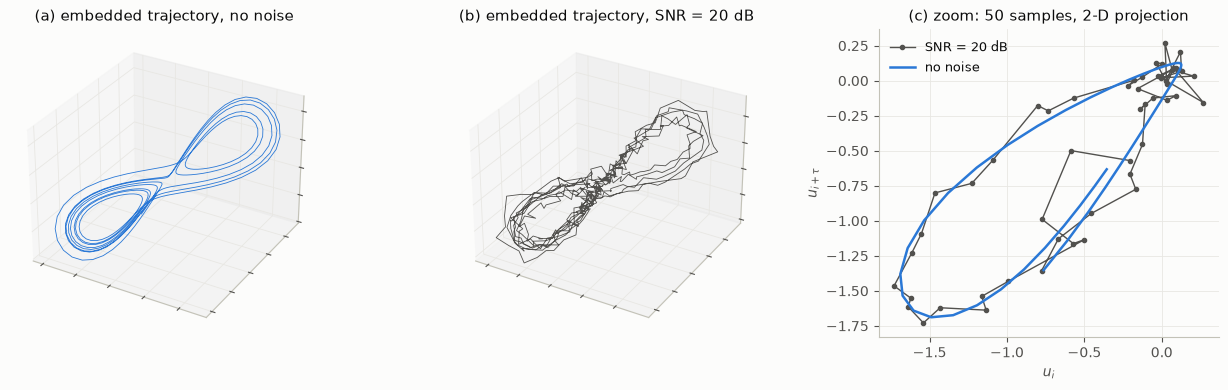

In [2]:
m28, tau28, N28 = 3, 3, 500                          # Fig. 1-2 settings, 500 x 500 RP
u  = xr.zscore(xr.lorenz(N28 + (m28 - 1) * tau28, rho=28, dt=0.02)[:, 0])
un = xr.add_noise(u, snr_db=20, seed=1)
X, Xn = xr.embed(u, m28, tau28), xr.embed(un, m28, tau28)

fig = plt.figure(figsize=(12.5, 4))
for k, (Z, name, col) in enumerate([(X, "no noise", C["clean"]), (Xn, "SNR = 20 dB", C["ink"])]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.plot(*Z.T, color=col, lw=0.6)
    ax.set_title(f"({'ab'[k]}) embedded trajectory, {name}")
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
ax = fig.add_subplot(1, 3, 3)
seg = slice(120, 170)
ax.plot(Xn[seg, 0], Xn[seg, 1], color=C["ink"], lw=1, marker="o", ms=3, label="SNR = 20 dB")
ax.plot(X[seg, 0], X[seg, 1], color=C["clean"], label="no noise")
ax.set(xlabel=r"$u_i$", ylabel=r"$u_{i+\tau}$", title="(c) zoom: 50 samples, 2-D projection")
ax.legend(loc="best")
fig.subplots_adjust(left=0.0, right=0.98, wspace=0.3)

## 2. Local-minima based RPs: LM, LMT and LM2P (Figs. 1d and 2)

For a reference state $x_i$, the distance profile $D_i(j)=\lVert x_i-x_j\rVert$ has a local minimum wherever the trajectory passes closest to $x_i$:

* **LM**: all local minima, $R_{ij}=1$ if $j$ is a local minimum of $D_i(\cdot)$
* **LMT** (Schultz et al. 2011): only minima with $D_{ij}\le\varepsilon$
* **LM2P** (this paper): LMT, and in addition minima of the same profile must be **at least τm samples apart**. The deepest minimum wins, as with `findpeaks(…, 'MinPeakDistance', τm)`.

Noise adds many shallow minima spaced about 3 samples apart, and τm removes them. ε is the 5th percentile of the clean distances, used for every panel as in the caption of Fig. 2(e, f). τm = 10.

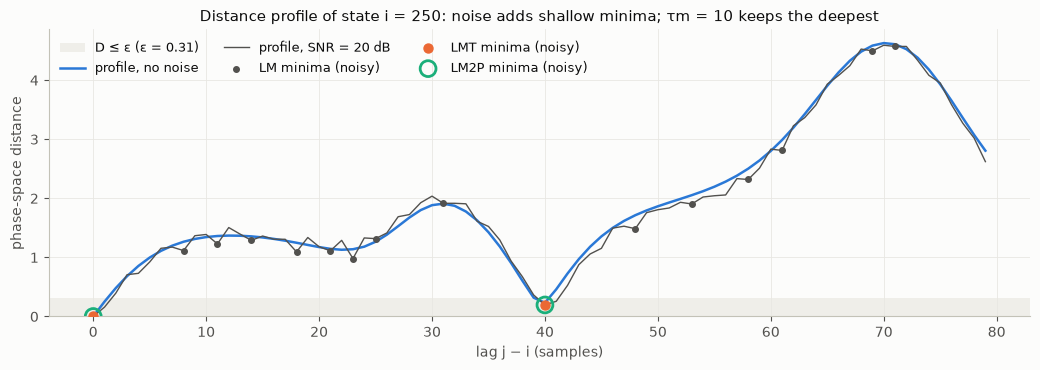

In [3]:
D, Dn = xr.distance_matrix(X), xr.distance_matrix(Xn)
eps = xr.eps_from_percentile(D, 5)
tau_m = 10
mins = {"LM": xr.local_minima_rp(Dn), "LMT": xr.local_minima_rp(Dn, eps), "LM2P": xr.local_minima_rp(Dn, eps, tau_m)}

i0, lags = 250, np.arange(0, 80)
j = i0 + lags
fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.axhspan(0, eps, color="#efeee9", lw=0, label=f"D ≤ ε (ε = {eps:.2f})")
ax.plot(lags, D[i0, j], color=C["clean"], label="profile, no noise")
ax.plot(lags, Dn[i0, j], color=C["ink"], lw=1, label="profile, SNR = 20 dB")
styles = {"LM":   dict(s=16, color=C["ink"]),
          "LMT":  dict(s=42, color=C["LMT"]),
          "LM2P": dict(s=130, facecolor="none", edgecolor=C["LM2P"], linewidths=2)}
for name, st in styles.items():
    sel = mins[name][i0, j].astype(bool)
    ax.scatter(lags[sel], Dn[i0, j][sel], zorder=3, label=f"{name} minima (noisy)", **st)
ax.set(xlabel="lag j − i (samples)", ylabel="phase-space distance", ylim=(0, None),
       title=f"Distance profile of state i = {i0}: noise adds shallow minima; τm = {tau_m} keeps the deepest")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()

RP (Fig. 2)                DET   LAM   paper DET paper LAM
(a) no noise, LMT         0.88  0.31        0.59      0.16
(c) noisy, threshold      0.78  0.84        0.50      0.51
(d) noisy, LM             0.07  0.94        0.05      0.85
(e) noisy, LMT            0.32  0.62        0.20      0.27
(f) noisy, LM2P           0.33  0.49        0.24      0.14


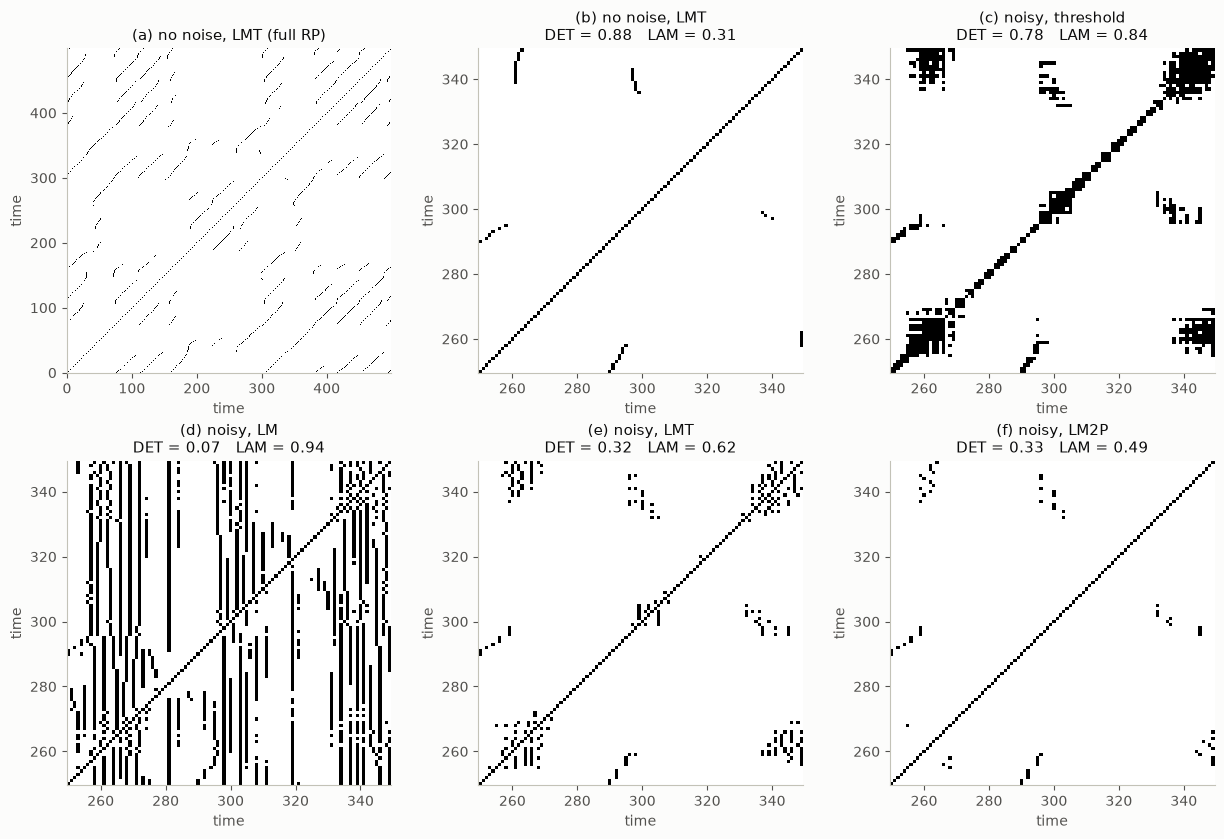

In [4]:
rps = {
    "(a) no noise, LMT":    xr.local_minima_rp(D, eps),
    "(c) noisy, threshold": xr.threshold_rp(Dn, xr.eps_from_percentile(Dn, 5)),
    "(d) noisy, LM":        mins["LM"],
    "(e) noisy, LMT":       mins["LMT"],
    "(f) noisy, LM2P":      mins["LM2P"],
}
paper = {"(a) no noise, LMT": (0.59, 0.16), "(c) noisy, threshold": (0.50, 0.51), "(d) noisy, LM": (0.046, 0.85),
         "(e) noisy, LMT": (0.20, 0.27), "(f) noisy, LM2P": (0.24, 0.14)}
q2 = {k: xr.rqa(R) for k, R in rps.items()}          # RQA on the full 500 x 500 RP

fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.4))
xr.plot_rp(rps["(a) no noise, LMT"], axes[0, 0], title="(a) no noise, LMT (full RP)")
panels = [("(b) no noise, LMT", "(a) no noise, LMT")] + [(k, k) for k in list(rps)[1:]]
for ax, (title, key) in zip(axes.flat[1:], panels):
    xr.plot_rp(rps[key], ax, 250, 350,
               title=f"{title}\nDET = {q2[key]['DET']:.2f}   LAM = {q2[key]['LAM']:.2f}")
plt.tight_layout()

print(f"{'RP (Fig. 2)':24s}{'DET':>6s}{'LAM':>6s}   {'paper DET':>9s}{'paper LAM':>10s}")
for k, q in q2.items():
    print(f"{k:24s}{q['DET']:6.2f}{q['LAM']:6.2f}   {paper[k][0]:9.2f}{paper[k][1]:10.2f}")

**What to look for** (zoom on samples 250–350, as in the paper):

* **(c) threshold RP**: thick lines and block clusters along and off the LOI. LAM is inflated (≈ 0.8, against ≈ 0.3 for the clean RP).
* **(d) LM**: every noisy wiggle is a minimum, giving long vertical lines and LAM ≈ 0.9. DET collapses.
* **(e) LMT**: the threshold removes most of LM's artefacts but leaves block clusters near the LOI and around recurrences.
* **(f) LM2P**: the block clusters are gone and the RP looks closest to (b). LAM drops relative to LMT. Short vertical stubs remain, so LAM stays above the clean value in this run, while the paper reports a near-perfect match. DET stays low, which motivates DDET.

The absolute DET/LAM values differ from the paper because the sampling step, record length and noise realisation are not reported. The ordering of the methods is reproduced.

## 3. Choosing τm (Fig. 3)

The paper's rule is that τm should be

* **larger** than the spacing of local minima that pure noise produces (Gaussian white noise: ≈ 3 samples), and
* **smaller** than the first lag where the ACF of the signal drops to ≤ 0.1, so that genuine recurrences are not merged.

`xr.suggest_tau_m(x, m, tau)` returns both bounds and their midpoint. From here on the setting of Figs. 6–10 is used: ρ = 80, dt = 0.01, m = 3, τ = 10, ε = 5th percentile, τm = 10, N = 1000.

suggest_tau_m(noisy Lorenz): {'lower': 3.0, 'upper': 23, 'recommended': 13} -> the paper's tau_m = 10 is inside the safe range


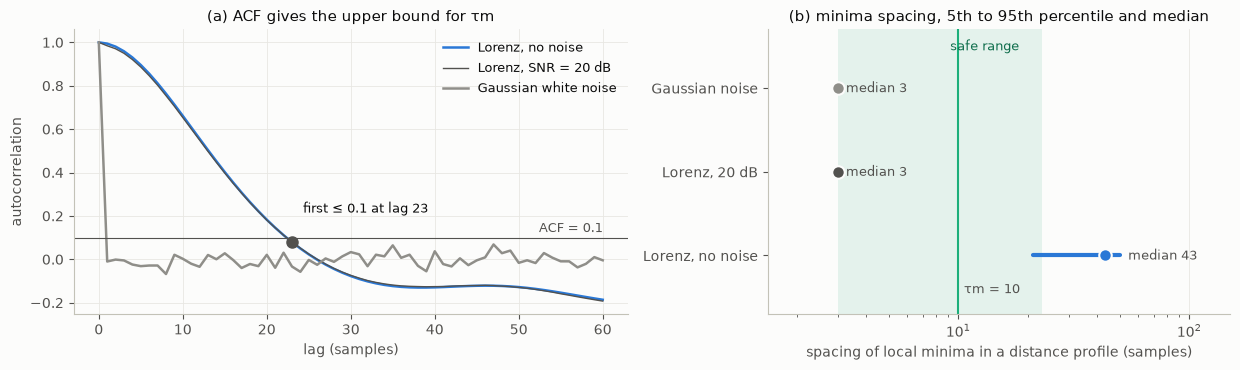

In [5]:
N, m, tau, tau_m = 1000, 3, 10, 10
n_raw = N + (m - 1) * tau
x  = xr.zscore(xr.lorenz(n_raw, rho=80, dt=0.01)[:, 0])
xn = xr.add_noise(x, snr_db=20, seed=1)
g  = np.random.default_rng(2).standard_normal(n_raw)                # stochastic reference
Ds = {k: xr.distance_matrix(xr.embed(s, m, tau)) for k, s in {"clean": x, "noisy": xn, "noise": g}.items()}

tm = xr.suggest_tau_m(xn, m=m, tau=tau)
print("suggest_tau_m(noisy Lorenz):", tm, f"-> the paper's tau_m = {tau_m} is inside the safe range")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
lag = np.arange(61)
for s, key, lab in [(x, "clean", "Lorenz, no noise"), (xn, "ink", "Lorenz, SNR = 20 dB"), (g, "noise", "Gaussian white noise")]:
    a1.plot(lag, xr.acf(s, 60), color=C[key], lw=1.8 if key != "ink" else 1, label=lab)
a1.axhline(0.1, color=C["ink"], lw=0.8)
a1.annotate("ACF = 0.1", (60, 0.1), xytext=(0, 4), textcoords="offset points", ha="right", color=C["ink"], fontsize=9)
c = xr.acf_first_crossing(xn)
a1.plot([c], [xr.acf(xn, c)[c]], "o", ms=8, color=C["ink"])
a1.annotate(f"first ≤ 0.1 at lag {c}", (c, 0.1), xytext=(8, 18), textcoords="offset points", fontsize=9)
a1.set(xlabel="lag (samples)", ylabel="autocorrelation", title="(a) ACF gives the upper bound for τm")
a1.legend(loc="upper right")

a2.axvspan(tm["lower"], tm["upper"], color="#e4f2ec", lw=0)
a2.annotate("safe range", ((tm["lower"] + tm["upper"]) / 2, 2.45), ha="center", color="#0f6e4c", fontsize=9)
a2.axvline(tau_m, color=C["LM2P"], lw=1.5)
a2.annotate(f"τm = {tau_m}", (tau_m, -0.45), xytext=(4, 0), textcoords="offset points", color=C["ink"], fontsize=9)
for y, (k, key) in enumerate([("clean", "clean"), ("noisy", "ink"), ("noise", "noise")]):
    sp = xr.minima_spacing(Ds[k])
    lo, med, hi = np.nanpercentile(sp, [5, 50, 95])
    a2.plot([lo, hi], [y, y], color=C[key], lw=3, solid_capstyle="round")
    a2.plot([med], [y], "o", ms=9, color=C[key], markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    a2.annotate(f"median {med:.0f}", (hi, y), xytext=(6, -3), textcoords="offset points", fontsize=9, color=C["ink"])
a2.set_yticks([0, 1, 2], ["Lorenz, no noise", "Lorenz, 20 dB", "Gaussian noise"])
a2.set(xscale="log", xlim=(1.5, 150), ylim=(-0.7, 2.7), xlabel="spacing of local minima in a distance profile (samples)",
       title="(b) minima spacing, 5th to 95th percentile and median")
a2.grid(axis="y", visible=False)
plt.tight_layout()

Noise lowers the minima spacing of the noisy Lorenz signal to about 3, the white-noise value. That is exactly the artefact LM2P removes. The clean Lorenz minima are typically ≈ 40 samples apart, and the ACF bound (≈ 20) is the more conservative upper limit.

## 4. DDET: determinism from a diagonal sliding window (Figs. 5–6)

A window of `ws` neighbouring diagonals slides from the LOI to the corner of the RP, starting every `tau_w` diagonals. In each window $w$:

1. $RR_w = \frac{1}{A_w}\sum_{(i,j)\in w} R_{ij}$, the recurrence rate over the $A_w$ cells of the window (Eq. 5);
2. the `ws` cells of every row are OR-ed into one binary sequence $d_k$ along the diagonal, which tolerates small sideways wiggles;
3. the gaps $D=\Delta k$ between consecutive $d_k = 1$ are collected, and gaps $\le D_{max}$ count as connected, which tolerates small disruptions;
4. $DD_w = \dfrac{\sum_{D\le D_{max}} D\,P(D)}{l_w-\sum_{D\le D_{max}} D\,P(D)}$, the connected length relative to the unconnected length of the window (Eq. 6);

$$DDET = \ln\frac{\langle DD_w\rangle_w}{\langle RR_w\rangle_w}.$$

Paper parameters: `ws = 2`, `tau_w = 2`, `d_max = 2` (a gap of one missing point is tolerated).

                             RR    DET    LAM    DDET
Lorenz, no noise          0.007   0.94   0.29   +0.73
Lorenz + noise, LMT       0.019   0.21   0.77   +0.83
Lorenz + noise, LM2P      0.008   0.25   0.63   +0.44
Gaussian white noise      0.030   0.06   0.08   -1.04


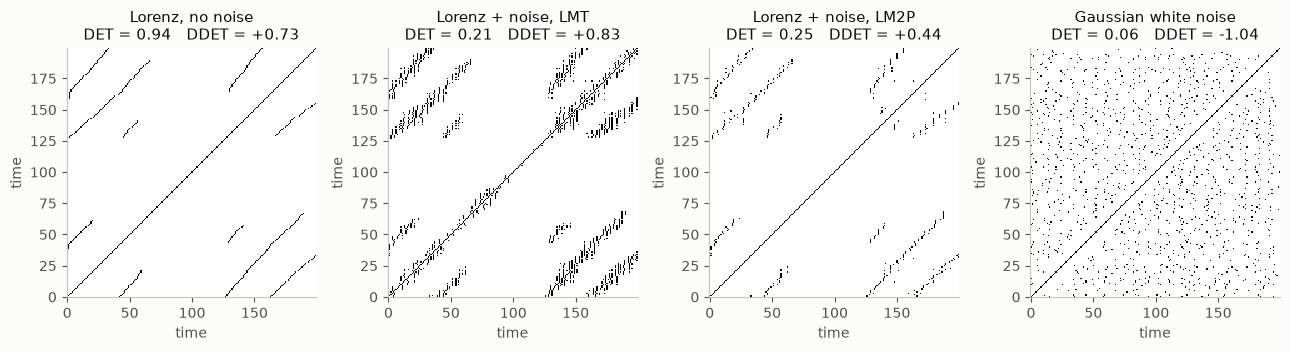

In [6]:
def rp_of(D, tm=tau_m):
    return xr.local_minima_rp(D, xr.eps_from_percentile(D, 5), tm)   # eps = 5th pct of the signal's own distances

R = {"clean": rp_of(Ds["clean"]), "LMT": rp_of(Ds["noisy"], None), "LM2P": rp_of(Ds["noisy"]), "noise": rp_of(Ds["noise"])}
res = {k: (xr.rqa(r), xr.ddet(r, ws=2, tau_w=2, d_max=2)) for k, r in R.items()}

print(f"{'':24s}{'RR':>7s}{'DET':>7s}{'LAM':>7s}{'DDET':>8s}")
for k, (q, d) in res.items():
    print(f"{LABEL[k]:24s}{q['RR']:7.3f}{q['DET']:7.2f}{q['LAM']:7.2f}{d.ddet:+8.2f}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, k in zip(axes, R):
    xr.plot_rp(R[k], ax, 0, 200, title=f"{LABEL[k]}\nDET = {res[k][0]['DET']:.2f}   DDET = {res[k][1].ddet:+.2f}")
plt.tight_layout()

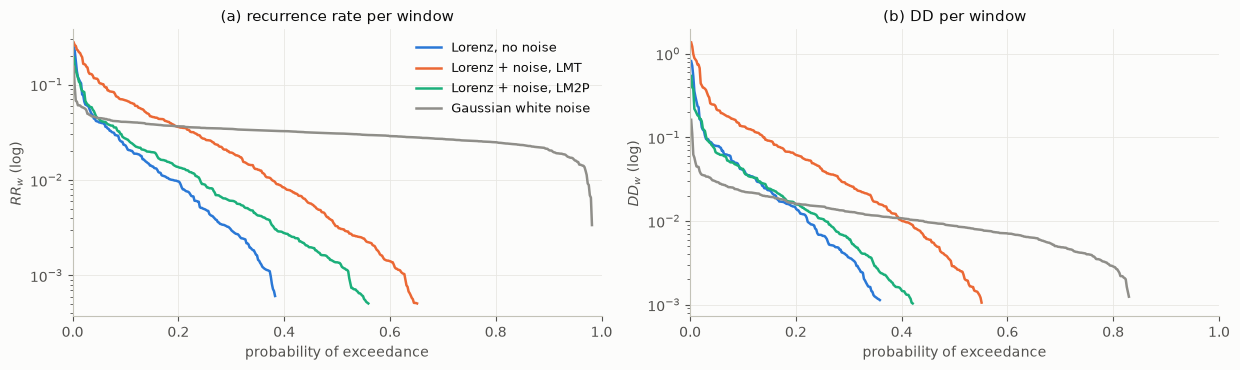

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
for k in R:
    d = res[k][1]
    for ax, v in [(a1, d.rr_w), (a2, d.dd_w)]:
        xr.plot_exceedance(v, ax, color=C[k], lw=1.8, label=LABEL[k])
a1.set(ylabel=r"$RR_w$ (log)", title="(a) recurrence rate per window")
a2.set(ylabel=r"$DD_w$ (log)", title="(b) DD per window")
for ax in (a1, a2):
    ax.set_xlim(0, 1)
a1.legend(loc="upper right")
plt.tight_layout()

**Reading the numbers.** With 20 dB noise, DET drops from ≈ 0.9 to ≈ 0.2–0.25, close to the stochastic reference. DDET stays clearly positive (Lorenz) and far from white noise (≈ −1). The window distributions (empty windows have value 0 and cannot appear on the log axis, so the curves end early) show the same picture as Fig. 6: white noise has a flat, high $RR_w$ in every window, while the deterministic RPs concentrate their recurrences in few windows. The LM2P curves of the noisy signal lie close to the clean ones, especially for $DD_w$. The LMT curves are shifted up by the noise-induced block clusters.

## 5. ρ sweep: DDET detects the periodic windows (Fig. 7)

Lorenz for ρ = 80…105 (step 0.5), with and without 20 dB noise. The maximum Lyapunov exponent (Benettin's two-trajectory method) marks the periodic windows P1 and P2, where it is ≈ 0. Conventional DET of the clean RP only reacts to P2. DDET marks both windows, even for the noisy signal.

The paper's Fig. 7b puts DET and DDET on two y-axes of one plot. Here they get separate panels, because two y-scales on one plot invite false comparisons.

In [8]:
rhos = np.arange(80, 105.01, 0.5)

def max_lyapunov(rhos, n=3000, dt=0.01, d0=1e-8):
    # Benettin estimate: two trajectories d0 apart, renormalised every step (all rho at once)
    a = xr.lorenz(1, rho=rhos, dt=dt)[:, -1]
    b = a + d0 / np.sqrt(3)
    acc = np.zeros(len(rhos))
    for _ in range(n):
        a = xr.lorenz(1, rho=rhos, dt=dt, transient=0, x0=a)[:, 0]
        b = xr.lorenz(1, rho=rhos, dt=dt, transient=0, x0=b)[:, 0]
        dist = np.linalg.norm(b - a, axis=1)
        acc += np.log(dist / d0)
        b = a + (b - a) * (d0 / dist)[:, None]
    return acc / (n * dt)

t0 = time.time()
lyap = max_lyapunov(rhos)
traj = xr.lorenz(n_raw, rho=rhos, dt=0.01)[:, :, 0]          # all rho integrated at once
keys = ["clean", "LMT", "LM2P"]
det, dd = {k: [] for k in keys}, {k: [] for k in keys}
r_rr, r_dd = {k: [] for k in keys[1:]}, {k: [] for k in keys[1:]}
for n, rho in enumerate(rhos):
    s = xr.zscore(traj[n])
    Dc = xr.distance_matrix(xr.embed(s, m, tau))
    Dn_ = xr.distance_matrix(xr.embed(xr.add_noise(s, 20, seed=n), m, tau))
    Rr = {"clean": rp_of(Dc), "LMT": rp_of(Dn_, None), "LM2P": rp_of(Dn_)}
    out = {k: xr.ddet(r) for k, r in Rr.items()}
    for k in keys:
        det[k].append(xr.rqa(Rr[k])["DET"])
        dd[k].append(out[k].ddet)
    for k in keys[1:]:
        r_rr[k].append(np.corrcoef(out["clean"].rr_w, out[k].rr_w)[0, 1])
        r_dd[k].append(np.corrcoef(out["clean"].dd_w, out[k].dd_w)[0, 1])
det, dd = {k: np.array(v) for k, v in det.items()}, {k: np.array(v) for k, v in dd.items()}
print(f"sweep done in {time.time() - t0:.0f} s")

periodic = lyap < 0.15                                            # ≈ 0 within numerical tolerance
def shade(ax):
    edges = np.flatnonzero(np.diff(np.r_[0, periodic.astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(rhos[a] - 0.25, rhos[b - 1] + 0.25, color="#efeee9", lw=0, zorder=0)
print("periodic rho (MLE ≈ 0):", rhos[periodic])

sweep done in 29 s
periodic rho (MLE ≈ 0): [ 92.   92.5  93.  100.  100.5]


Lorenz, no noise       DET  chaotic 0.93  periodic 0.94   |   DDET chaotic +0.72 (median)  periodic +6.13
Lorenz + noise, LMT    DET  chaotic 0.24  periodic 0.28   |   DDET chaotic +0.73 (median)  periodic +1.82
Lorenz + noise, LM2P   DET  chaotic 0.28  periodic 0.32   |   DDET chaotic +0.48 (median)  periodic +1.22


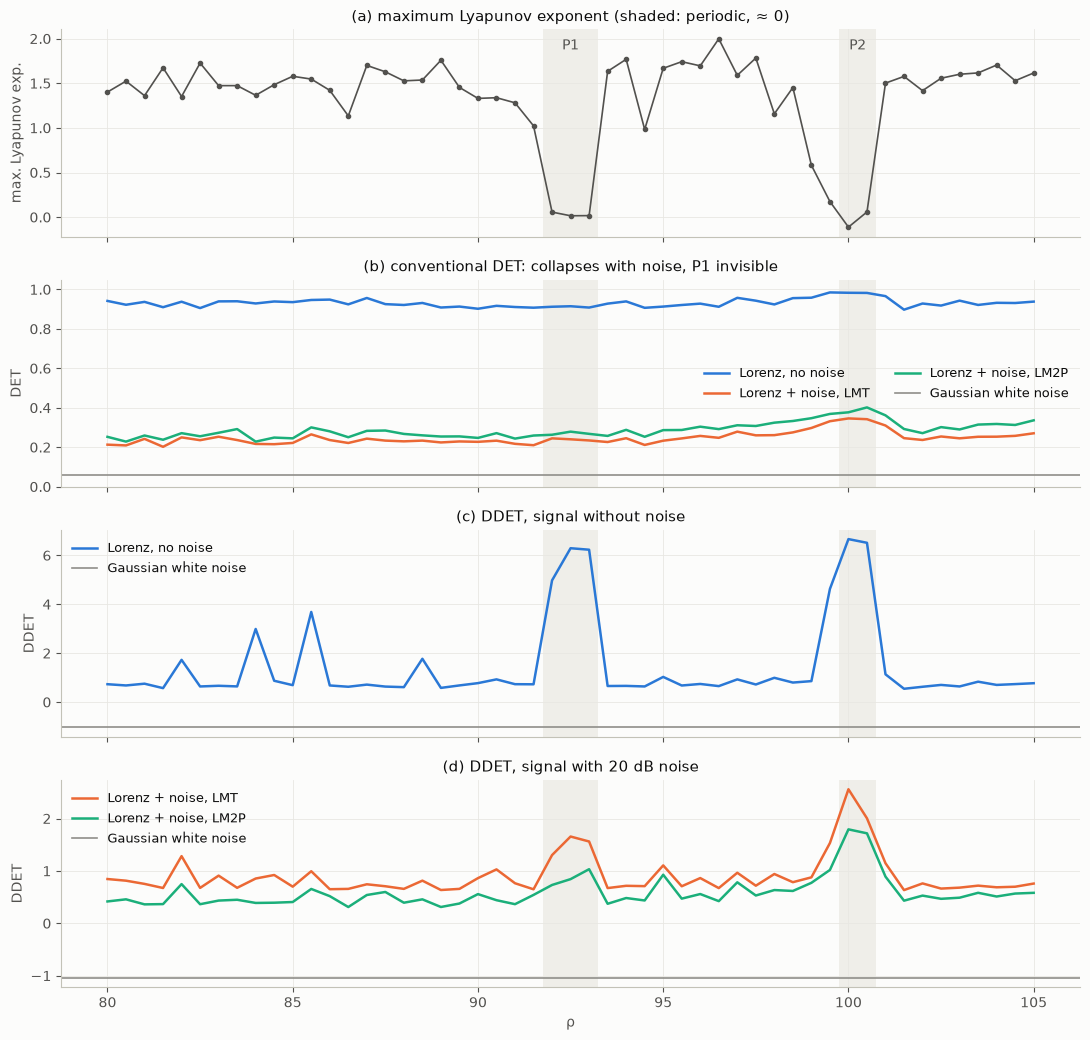

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10.5), sharex=True)
ax = axes[0]; shade(ax)
ax.plot(rhos, lyap, color=C["ink"], marker="o", ms=3, lw=1.2)
ax.set(ylabel="max. Lyapunov exp.", title="(a) maximum Lyapunov exponent (shaded: periodic, ≈ 0)")
for name, lo, hi in [("P1", 91, 95), ("P2", 98, 102)]:
    sel = periodic & (rhos > lo) & (rhos < hi)
    if sel.any():
        ax.annotate(name, (rhos[sel].mean(), lyap.max()), ha="center", va="top", fontsize=10, color=C["ink"])

ax = axes[1]; shade(ax)
for k in keys:
    ax.plot(rhos, det[k], color=C[k], label=LABEL[k])
ax.axhline(res["noise"][0]["DET"], color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DET", ylim=(0, 1.05), title="(b) conventional DET: collapses with noise, P1 invisible")
ax.legend(loc="center right", ncol=2)

ax = axes[2]; shade(ax)
ax.plot(rhos, dd["clean"], color=C["clean"], label=LABEL["clean"])
ax.axhline(res["noise"][1].ddet, color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DDET", title="(c) DDET, signal without noise")
ax.legend(loc="upper left")

ax = axes[3]; shade(ax)
for k in keys[1:]:
    ax.plot(rhos, dd[k], color=C[k], label=LABEL[k])
ax.axhline(res["noise"][1].ddet, color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DDET", xlabel="ρ", title="(d) DDET, signal with 20 dB noise")
ax.legend(loc="upper left")
plt.tight_layout()

for k in keys:
    print(f"{LABEL[k]:22s} DET  chaotic {det[k][~periodic].mean():.2f}  periodic {det[k][periodic].mean():.2f}   |   "
          f"DDET chaotic {np.median(dd[k][~periodic]):+.2f} (median)  periodic {dd[k][periodic].mean():+.2f}")

mean r(RR_w): {'LMT': 0.79, 'LM2P': 0.91}   mean r(DD_w): {'LMT': 0.81, 'LM2P': 0.85}


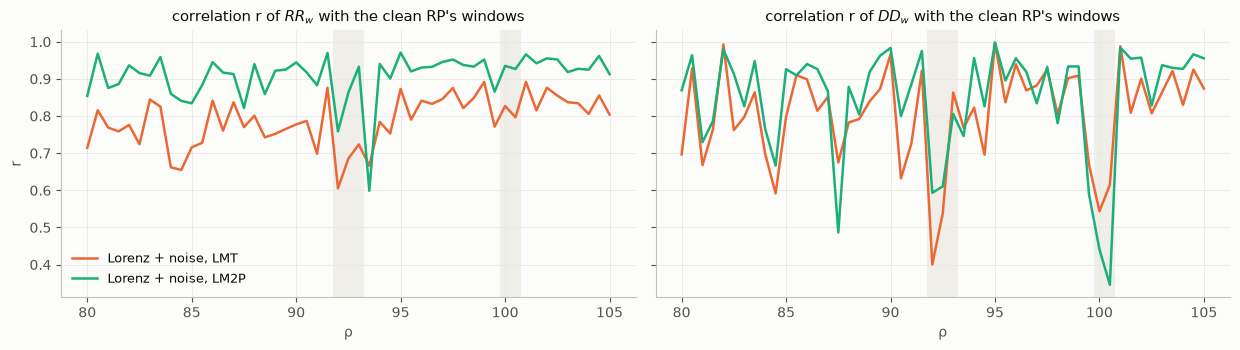

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
for ax, r, name in [(a1, r_rr, r"$RR_w$"), (a2, r_dd, r"$DD_w$")]:
    shade(ax)
    for k in keys[1:]:
        ax.plot(rhos, r[k], color=C[k], label=LABEL[k])
    ax.set(xlabel="ρ", title=f"correlation r of {name} with the clean RP's windows")
a1.set_ylabel("r")
a1.legend(loc="lower left")
plt.tight_layout()
print("mean r(RR_w):", {k: round(float(np.mean(v)), 2) for k, v in r_rr.items()},
      "  mean r(DD_w):", {k: round(float(np.mean(v)), 2) for k, v in r_dd.items()})

**Result.**

* **DET** of the clean RP is ≈ 0.9 everywhere and only rises at P2. With noise it collapses to ≈ 0.2–0.4 (panel b).
* **DDET** jumps in both P1 and P2, both without noise (c) and with 20 dB noise (d). All Lorenz values stay well above white noise (≈ −1), as in Fig. 7b.
* The window-wise agreement with the clean RP (Fig. 6c,d) is better for LM2P than for LMT, most clearly in $RR_w$.
* LMT gives *higher* DDET values than LM2P, but those are inflated by the noise-induced block clusters, and its windows agree less with the clean RP.
* The clean curve has a few isolated spikes in the chaotic range. See section 9 for the cause.

## 6. Sensitivity: noise level, window size `ws`, embedding dimension `m` (Figs. 8–10)

chaotic (ρ = 80)     SNR [30, 25, 20, 15, 10, 5] dB
   DET  [0.53 0.37 0.24 0.17 0.11 0.07] (no noise 0.94)
   DDET [ 0.75  0.61  0.33 -0.06 -0.43 -0.68] (no noise 0.73)


periodic (ρ = 100)   SNR [30, 25, 20, 15, 10, 5] dB
   DET  [0.77 0.58 0.37 0.21 0.12 0.08] (no noise 0.98)
   DDET [ 5.35  3.13  1.52  0.53 -0.1  -0.59] (no noise 6.66)


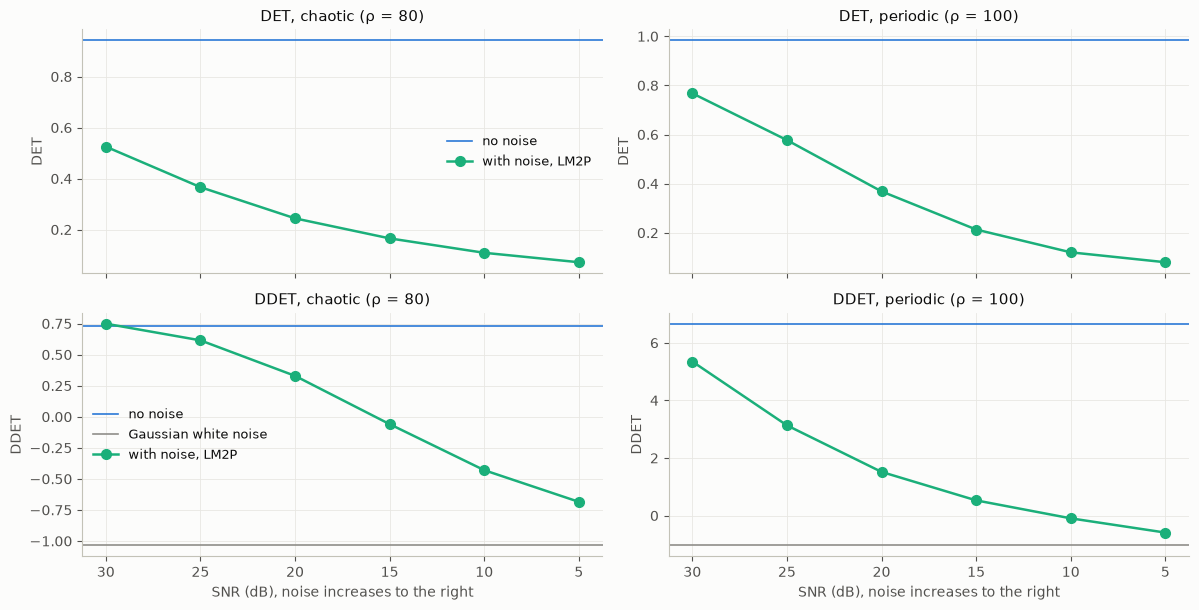

In [11]:
snrs = np.array([30, 25, 20, 15, 10, 5])
cases = {"chaotic (ρ = 80)": x, "periodic (ρ = 100)": xr.zscore(xr.lorenz(n_raw, rho=100, dt=0.01)[:, 0])}
lm2p = lambda s: rp_of(xr.distance_matrix(xr.embed(s, m, tau)))

fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True)
for col, (name, s) in enumerate(cases.items()):
    Rc = lm2p(s)
    det0, ddet0 = xr.rqa(Rc)["DET"], xr.ddet(Rc).ddet
    Rs_ = [lm2p(xr.add_noise(s, snr, seed=3)) for snr in snrs]
    dets = [xr.rqa(r)["DET"] for r in Rs_]
    ddets = [xr.ddet(r).ddet for r in Rs_]
    for row, (vals, ref, lab) in enumerate([(dets, det0, "DET"), (ddets, ddet0, "DDET")]):
        ax = axes[row, col]
        ax.axhline(ref, color=C["clean"], lw=1.2, label="no noise")
        if row == 1:
            ax.axhline(res["noise"][1].ddet, color=C["noise"], lw=1.2, label="Gaussian white noise")
        ax.plot(snrs, vals, color=C["LM2P"], marker="o", ms=7, label="with noise, LM2P")
        ax.set(ylabel=lab, title=f"{lab}, {name}")
    print(f"{name:20s} SNR {snrs.tolist()} dB\n   DET  {np.round(dets, 2)} (no noise {det0:.2f})"
          f"\n   DDET {np.round(ddets, 2)} (no noise {ddet0:.2f})")
for ax in axes[1]:
    ax.set_xlabel("SNR (dB), noise increases to the right")
axes[0, 0].invert_xaxis()                     # x is shared by all four panels
axes[0, 0].legend(loc="center right"); axes[1, 0].legend(loc="center left")
plt.tight_layout()

DET drops sharply already at 30 dB (0.94 → 0.53 chaotic, 0.98 → 0.77 periodic). For chaotic dynamics DDET stays at its noise-free value down to ≈ 25 dB and remains well above the white-noise level (≈ −1) at 20 dB. Periodic DDET falls steadily but stays above the chaotic level down to 20 dB. Below ≈ 15 dB DDET moves towards the white-noise value and is no longer reliable, which matches the paper's conclusion (Fig. 10).

DDET vs ws [2, 3, 4, 6, 10, 20]
   Lorenz, no noise       [0.73 1.23 1.62 2.15 3.3  4.14]
   Lorenz + noise, LMT    [0.83 1.37 1.64 2.05 2.8  3.41]
   Lorenz + noise, LM2P   [0.44 1.08 1.5  2.07 3.15 4.06]
   Gaussian white noise   [-1.04 -0.16  0.37  1.17  2.23  3.6 ]
DDET vs m  [1, 2, 3, 5, 8, 12]
   Lorenz, no noise       [-0.07  0.66  0.73  0.72  0.76  1.13]
   Lorenz + noise, LMT    [0.4  0.78 0.83 0.88 0.86 0.9 ]
   Lorenz + noise, LM2P   [-0.14  0.24  0.42  0.51  0.51  0.8 ]
   Gaussian white noise   [-0.88 -1.   -1.04 -1.01 -0.98 -0.91]


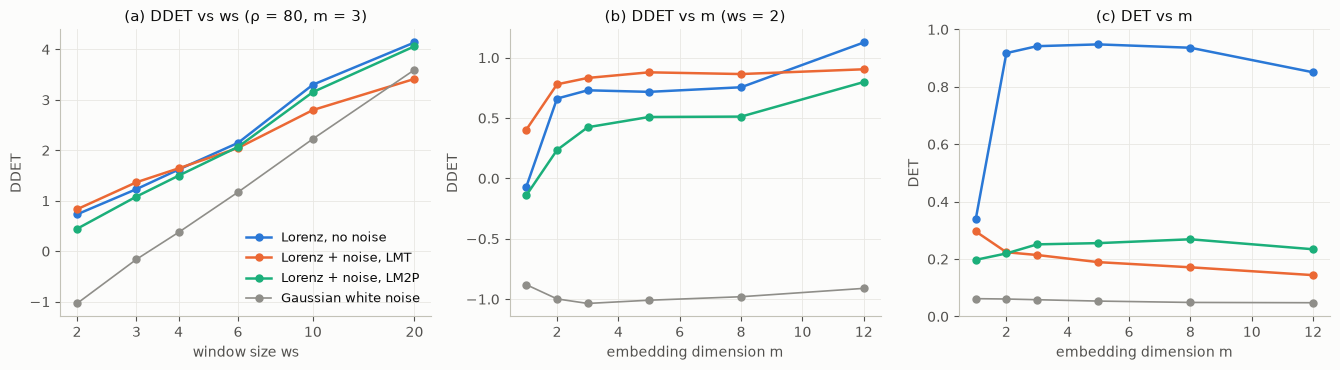

In [12]:
ws_list = [2, 3, 4, 6, 10, 20]
m_list = [1, 2, 3, 5, 8, 12]
xl = xr.zscore(xr.lorenz(N + 11 * tau, rho=80, dt=0.01)[:, 0])     # long enough for m = 12
xln = xr.add_noise(xl, 20, seed=1)
gl = np.random.default_rng(2).standard_normal(N + 11 * tau)

ws_res = {k: [xr.ddet(R[k], ws=w).ddet for w in ws_list] for k in R}
m_res = {k: [] for k in R}
for mm in m_list:
    n_ = N + (mm - 1) * tau
    Dm = {k: xr.distance_matrix(xr.embed(s[:n_], mm, tau)) for k, s in {"clean": xl, "noisy": xln, "noise": gl}.items()}
    Rm = {"clean": rp_of(Dm["clean"]), "LMT": rp_of(Dm["noisy"], None), "LM2P": rp_of(Dm["noisy"]), "noise": rp_of(Dm["noise"])}
    for k in R:
        m_res[k].append((xr.rqa(Rm[k])["DET"], xr.ddet(Rm[k]).ddet))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for k in R:
    lw = 1.2 if k == "noise" else 1.8
    axes[0].plot(ws_list, ws_res[k], color=C[k], marker="o", lw=lw, label=LABEL[k])
    axes[1].plot(m_list, [v[1] for v in m_res[k]], color=C[k], marker="o", lw=lw, label=LABEL[k])
    axes[2].plot(m_list, [v[0] for v in m_res[k]], color=C[k], marker="o", lw=lw, label=LABEL[k])
axes[0].set(xlabel="window size ws", ylabel="DDET", title="(a) DDET vs ws (ρ = 80, m = 3)", xscale="log")
axes[0].set_xticks(ws_list, [str(w) for w in ws_list]); axes[0].minorticks_off()
axes[1].set(xlabel="embedding dimension m", ylabel="DDET", title="(b) DDET vs m (ws = 2)")
axes[2].set(xlabel="embedding dimension m", ylabel="DET", ylim=(0, 1), title="(c) DET vs m")
axes[0].legend(loc="lower right")
plt.tight_layout()
print("DDET vs ws", ws_list); [print(f"   {LABEL[k]:22s}", np.round(v, 2)) for k, v in ws_res.items()]
print("DDET vs m ", m_list); [print(f"   {LABEL[k]:22s}", np.round([v[1] for v in m_res[k]], 2)) for k in m_res];

* **ws (a).** At `ws = 2` the noisy LM2P value is close to the clean one and white noise sits at ≈ −1. With larger `ws` the OR-aggregation saturates, so DDET grows for every signal. White noise grows fastest: its gap to the clean Lorenz value shrinks from ≈ 1.8 at `ws = 2` to ≈ 0.5 at `ws = 20`, where noise even exceeds the noisy LMT value. Keep `ws` small (2–3), as the paper recommends.
  *Deviation:* the paper's Fig. 9 shows DDET *decreasing* with `ws`. This implementation follows the literal Eq. 5 normalisation by window area, which reproduces the paper's values at `ws = 2` but gives the opposite trend for larger `ws` (see section 9).
* **m (b, c).** With noise, DET stays low for every embedding dimension. DDET of the noisy signal stays positive and separated from noise (≈ −1) for every `m` ≥ 2, so a low embedding dimension is enough (paper, Fig. 8).

## 7. Distance from random noise

The sections above compare Lorenz with a single white-noise RP at ≈ −1. That value depends on the settings (`ddet_white_noise.ipynb`), so here every value is compared with a baseline computed with this notebook's settings: 20 Gaussian white-noise series analysed exactly like the signal. `xr.ddet_baseline` returns the DDET and the DET of these series.

$\Delta DDET = DDET - \overline{DDET}_{noise}$ and $\Delta DET = DET - \overline{DET}_{noise}$. ΔDDET is a log ratio: ΔDDET = 2 means 7.4 times more connected diagonal structure than noise. ΔDET is a plain difference of fractions, at most 1 − baseline. Because the units differ, the table also gives scale-free numbers: the closest chaotic value in white-noise standard deviations, and the AUC for telling periodic from chaotic values. The AUC is the probability that a periodic ρ scores higher than a chaotic one (1 = perfect separation, 0.5 = none).

white-noise baseline, 20 series: DDET -1.05 ± 0.07 (model -1.05),  DET 0.057 ± 0.003

                         median Δ, chaotic  median Δ, periodic    closest chaotic (noise sd)  AUC periodic vs chaotic
                             DDET      DET      DDET       DET           DDET            DET        DDET          DET
Lorenz, no noise            +1.77    +0.87     +7.34     +0.86    +1.60 ( 23)    +0.84 (270)        1.00         0.50
Lorenz + noise, LM2P        +1.53    +0.22     +2.09     +0.22    +1.36 ( 20)    +0.17 ( 55)        0.96         0.65


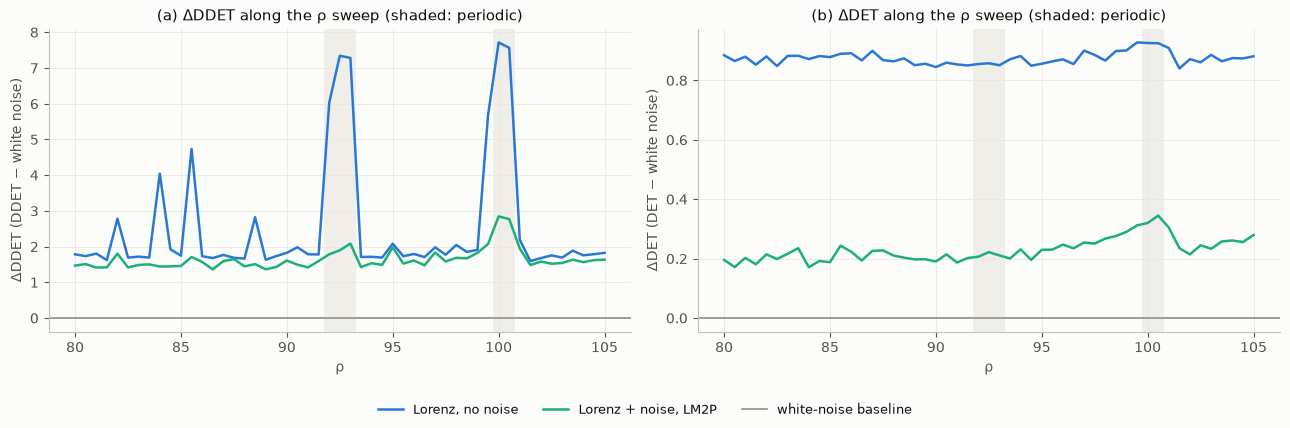

In [13]:
base = xr.ddet_baseline(n=n_raw, m=m, tau=tau, tau_m=tau_m, n_real=20, seed=0)    # white noise, this notebook's settings
delta = {"DDET": {k: dd[k] - base["mean"] for k in ("clean", "LM2P")},
         "DET":  {k: det[k] - base["det_mean"] for k in ("clean", "LM2P")}}

def auc(v):                                        # P(periodic value > chaotic value), ties count half
    a, b = v[periodic][:, None], v[~periodic][None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
for ax, (lab, v), tag in zip(axes, delta.items(), "ab"):
    shade(ax)
    ax.axhline(0, color=C["noise"], lw=1.2)
    for k in ("clean", "LM2P"):
        ax.plot(rhos, v[k], color=C[k])
    ax.set(xlabel="ρ", ylabel=f"Δ{lab} ({lab} − white noise)", title=f"({tag}) Δ{lab} along the ρ sweep (shaded: periodic)")
handles = [Line2D([], [], color=C[k], label=LABEL[k]) for k in ("clean", "LM2P")] + [Line2D([], [], color=C["noise"], lw=1.2, label="white-noise baseline")]
fig.legend(handles=handles, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1))

print(f"white-noise baseline, 20 series: DDET {base['mean']:+.2f} ± {base['sd']:.2f} (model {base['theory']:+.2f}),  DET {base['det_mean']:.3f} ± {base['det_sd']:.3f}\n")
print(f"{'':24s}{'median Δ, chaotic':>18s}{'median Δ, periodic':>20s}{'closest chaotic (noise sd)':>30s}{'AUC periodic vs chaotic':>25s}")
print(f"{'':24s}{'DDET':>9s}{'DET':>9s}{'DDET':>10s}{'DET':>10s}{'DDET':>15s}{'DET':>15s}{'DDET':>12s}{'DET':>13s}")
for k in ("clean", "LM2P"):
    dD, dT = delta["DDET"][k], delta["DET"][k]
    cD, cT = dD[~periodic].min(), dT[~periodic].min()
    print(f"{LABEL[k]:24s}{np.median(dD[~periodic]):+9.2f}{np.median(dT[~periodic]):+9.2f}{np.median(dD[periodic]):+10.2f}{np.median(dT[periodic]):+10.2f}"
          f"{cD:+9.2f} ({cD / base['sd']:3.0f}){cT:+9.2f} ({cT / base['det_sd']:3.0f}){auc(dd[k]):12.2f}{auc(det[k]):13.2f}")

* With this notebook's settings, white noise gives DDET −1.05 ± 0.07 and DET 0.057 ± 0.003, so the single noise RP of section 4 (≈ −1) was representative.
* **DDET.** Chaotic Lorenz is +1.77 above white noise without noise and +1.53 with 20 dB noise. The closest chaotic value is +1.36, 20 noise standard deviations away. The periodic windows reach +7.3 without noise but only +2.1 with noise, still enough to separate them from chaos (AUC 0.96).
* **DET.** Without noise, ΔDET is ≈ +0.87 for every ρ. It reacts to P2 but not to P1, so it cannot tell periodic from chaotic values (AUC 0.50). With noise it falls to +0.22 for both regimes (AUC 0.65). Because white-noise DET hardly varies, even +0.17 is 55 noise standard deviations away. DET does say "not white noise", but nothing more.

**Signal or noise, as the noise grows?** The chaotic Lorenz signal (ρ = 80) is cut into 20 segments of the same length, and each segment gets its own noise. The 20 values are compared with 20 noise series:

* **white noise**: the 20 baseline series above;
* **red noise**: AR(1) noise with the same lag-1 autocorrelation φ as the noisy signal (`xr.ar1_noise`). This is the usual "red noise" null hypothesis: noise with memory, as most real measurement noise has.

AUC is the probability that a signal segment scores higher than a noise series. 1 means the signal is always recognised, 0.5 is chance, and below 0.5 the noise looks *more* deterministic than the signal. Markers are shifted slightly sideways so that overlapping values stay visible. The procedure is the same as in `ddet_white_noise.ipynb` (B5).

AUC, chaotic Lorenz (ρ = 80) vs noise: 20 segments against 20 noise series
                         20 dB   15 dB   10 dB    5 dB    0 dB   -5 dB
DDET vs white noise       1.00    1.00    1.00    1.00    0.92    0.55
DET  vs white noise       1.00    1.00    1.00    1.00    0.87    0.46
DDET vs red noise         1.00    1.00    0.83    0.48    0.50    0.31
DET  vs red noise         1.00    0.98    0.00    0.00    0.01    0.14
φ of the noisy signal    0.986   0.966   0.908   0.764   0.512   0.258
done in 67 s


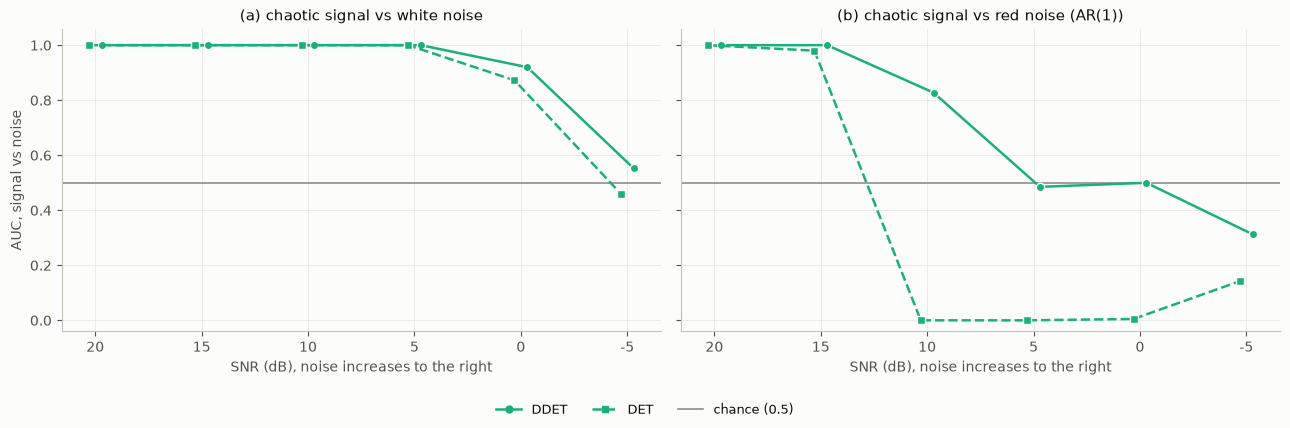

In [14]:
snrs_auc, K = [20, 15, 10, 5, 0, -5], 20

def auc_ab(a, b):                                  # P(a > b) over all pairs, ties count half
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

def ddet_det(s):
    r = lm2p(s)
    return xr.ddet(r).ddet, xr.rqa(r)["DET"]

t0 = time.time()
long_ = xr.lorenz(n_raw * K, rho=80, dt=0.01)[:, 0]
segs = [xr.zscore(long_[i * n_raw:(i + 1) * n_raw]) for i in range(K)]
white = np.c_[base["values"], base["det_values"]]                  # (20, 2): DDET, DET
auc_sn = {(null, j): [] for null in ("white", "red") for j in (0, 1)}
phis = []
for snr in snrs_auc:
    noisy_ = [xr.add_noise(s, snr, seed=100 * i + 7) for i, s in enumerate(segs)]
    sig_ = np.array([ddet_det(s) for s in noisy_])
    phi = float(np.mean([np.corrcoef(s[:-1], s[1:])[0, 1] for s in noisy_]))
    rng = np.random.default_rng(1)
    red = np.array([ddet_det(xr.ar1_noise(n_raw, phi, rng)) for _ in range(K)])
    phis.append(phi)
    for j in (0, 1):
        auc_sn[("white", j)].append(auc_ab(sig_[:, j], white[:, j]))
        auc_sn[("red", j)].append(auc_ab(sig_[:, j], red[:, j]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True, sharey=True)
for ax, null, title in zip(axes, ("white", "red"), ("(a) chaotic signal vs white noise", "(b) chaotic signal vs red noise (AR(1))")):
    ax.axhline(0.5, color=C["noise"], lw=1.2)
    for j, ls, mk, dx in [(0, "-", "o", -0.3), (1, "--", "s", 0.3)]:
        ax.plot(np.array(snrs_auc) + dx, auc_sn[(null, j)], color=C["LM2P"], ls=ls, marker=mk, ms=6, mec="#fcfcfb", mew=1)
    ax.set_xticks(snrs_auc, [str(v) for v in snrs_auc])
    ax.set(xlabel="SNR (dB), noise increases to the right", title=title)
axes[0].invert_xaxis()                                              # x is shared
axes[0].set(ylabel="AUC, signal vs noise", ylim=(-0.04, 1.06))
handles = [Line2D([], [], color=C["LM2P"], ls="-", marker="o", label="DDET"), Line2D([], [], color=C["LM2P"], ls="--", marker="s", label="DET"),
           Line2D([], [], color=C["noise"], lw=1.2, label="chance (0.5)")]
fig.legend(handles=handles, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1))

print(f"AUC, chaotic Lorenz (ρ = 80) vs noise: {K} segments against {K} noise series")
print(f"{'':22s}" + "".join(f"{str(v) + ' dB':>8s}" for v in snrs_auc))
for (null, j), v in auc_sn.items():
    print(f"{['DDET', 'DET'][j]:5s}vs {null + ' noise':14s}" + "".join(f"{a:8.2f}" for a in v))
print(f"{'φ of the noisy signal':22s}" + "".join(f"{p_:8.3f}" for p_ in phis))
print(f"done in {time.time() - t0:.0f} s")

* **Against white noise**, both measures recognise chaotic Lorenz down to 5 dB (AUC 1.00) and almost at 0 dB (DDET 0.92, DET 0.87).
* **Against red noise** (φ ≈ 0.99 at 20 dB), DET breaks down first. At 10 dB the AR(1) noise has the higher DET in every pair (AUC 0.00, mean 0.13 against 0.10 for the signal). DDET still gives 0.83 at 10 dB and reaches chance at 5 dB.
* Lorenz is the hardest of the four example systems in this test (compare section 7 of the other notebooks). With the paper's m = 3 and about 40 samples per oscillation, its DDET falls fastest with noise. Coarser sampling and m = 5 help (see the other examples).

## 8. Recipe for your own data

1. Use an evenly sampled 1-D series. Choose `m` and `tau` as usual, for example with false nearest neighbours and mutual information.
2. Pick `tau_m` between the white-noise minima spacing and the first ACF ≤ 0.1 lag (`suggest_tau_m`).
3. Build the LM2P RP, then compute RQA and DDET with `ws = 2`, `tau_w = 2`, `d_max = 2`.
4. Compare DDET and DET with surrogates computed with the same settings (`xr.ddet_baseline`):
   * **shuffled** surrogates destroy all temporal order but keep the value distribution: white noise for your data;
   * **AR(1)** surrogates (`surrogate="ar1"`) are red noise with the lag-1 memory of your series, the harder test (section 7).

   Report the distance (Δ = value − surrogate mean, also in surrogate standard deviations). With 20 surrogates, a value above all of them is significant at p ≈ 1/21 ≈ 0.05 (one-sided rank test).

In [15]:
series = xn                    # <- replace with your own series, e.g. np.loadtxt("my_series.txt")
m_, tau_ = 3, 10               # <- your embedding

s = xr.zscore(series)
tm_ = xr.suggest_tau_m(s, m=m_, tau=tau_)["recommended"]
R_ = xr.recurrence_plot(s, m=m_, tau=tau_, method="lm2p", perc=5, tau_m=tm_)
q_, d_ = xr.rqa(R_), xr.ddet(R_, ws=2, tau_w=2, d_max=2)

print(f"tau_m = {tm_}:  DET = {q_['DET']:.2f}  LAM = {q_['LAM']:.2f}  DDET = {d_.ddet:+.2f}")
print(d_, "\n")
for kind in ("shuffle", "ar1"):
    b = xr.ddet_baseline(x=s, m=m_, tau=tau_, tau_m=tm_, surrogate=kind, n_real=20, seed=0)
    name = "shuffled" if kind == "shuffle" else f"AR(1), phi = {b['phi']:.3f}"
    for lab, v, mu, sd, vals in [("DDET", d_.ddet, b["mean"], b["sd"], b["values"]), ("DET", q_["DET"], b["det_mean"], b["det_sd"], b["det_values"])]:
        verdict = "above all 20 surrogates (p ≈ 0.05)" if v > vals.max() else "not distinguishable from these surrogates"
        print(f"{name:22s} {lab:4s} surrogates {mu:+.3f} ± {sd:.3f}   Δ{lab} = {v - mu:+.2f} ({(v - mu) / sd:4.0f} sd)   {verdict}")

tau_m = 13:  DET = 0.26  LAM = 0.63  DDET = +0.46
DDETResult(ddet=0.456, n_windows=499, mean_RR_w=0.0093, mean_DD_w=0.0146) 



shuffled               DDET surrogates -1.127 ± 0.047   ΔDDET = +1.58 (  34 sd)   above all 20 surrogates (p ≈ 0.05)
shuffled               DET  surrogates +0.054 ± 0.003   ΔDET = +0.20 (  58 sd)   above all 20 surrogates (p ≈ 0.05)


AR(1), phi = 0.986     DDET surrogates -0.303 ± 0.042   ΔDDET = +0.76 (  18 sd)   above all 20 surrogates (p ≈ 0.05)
AR(1), phi = 0.986     DET  surrogates +0.122 ± 0.009   ΔDET = +0.13 (  15 sd)   above all 20 surrogates (p ≈ 0.05)


## 9. Implementation notes and interpretation choices

The paper gives no code, and a few details had to be interpreted. All of them are documented in the docstrings and can be changed in one place:

| aspect | choice in `exrqa` | why |
|---|---|---|
| orientation | minima of each row profile $D_i(\cdot)$; LAM counts runs in columns | the only orientation in which LM produces the long vertical lines and high LAM of Fig. 2d. Strict minima cannot be adjacent along the search direction. |
| LM2P rule | threshold ε first, then deepest-first suppression of minima closer than τm | same order as `findpeaks` with `MinPeakHeight` and `MinPeakDistance` |
| ε | 5th percentile of the signal's own off-diagonal distances (Fig. 2 uses the clean ε) | practical, since real data has no clean twin |
| Eq. 6 | $P(D)$ = gap counts; denominator = $l_w$ − connected length; $A_w$ = cells in the `ws` diagonals; natural log | reproduces white noise ≈ −1 and the $RR_w$, $DD_w$ magnitudes of Fig. 6 |
| windows | upper triangle, lags 1 … N − ws (LOI excluded) | Fig. 5a. Use `R.T` for the other triangle. |
| RQA | Theiler window 1 (LOI excluded); diagonal lines from both triangles | LM-type RPs are not symmetric |

**Known deviations from the paper's figures.** Some differences are expected, because sampling step, record length and noise realisation are not reported:

* Absolute DET/LAM differ, and LM2P's LAM reduction is weaker than in the paper.
* Periodic DDET values are higher than the paper's 2–3.
* DDET increases with `ws` instead of decreasing (Fig. 9).

The large periodic values come from Eq. 6 itself. When one line fills a whole window, the denominator drops to 1 and $DD_w \approx l_w$. The same thing produces the isolated spikes of the clean chaotic curve in section 5, when a line happens to fill a *short* window near the RP corner. `ddet(..., max_lag=N // 2)` drops those corner windows:

In [16]:
chaotic = lyap > 0.5                                             # clearly chaotic, away from P1/P2
k = int(np.argmax(np.where(chaotic, dd["clean"], -np.inf)))       # the largest spike in the chaotic range
s = xr.zscore(traj[k])
Rk = rp_of(xr.distance_matrix(xr.embed(s, m, tau)))
full, half = xr.ddet(Rk), xr.ddet(Rk, max_lag=N // 2)
top = int(np.argmax(full.dd_w))
print(f"rho = {rhos[k]}: DDET = {full.ddet:+.2f}; the window at lag {full.offsets[top]} "
      f"(length {N - full.offsets[top]}) has DD_w = {full.dd_w[top]:.0f}, "
      f"{full.dd_w[top] / full.dd_w.sum():.0%} of the sum of all DD_w")
print(f"with max_lag = N/2: DDET = {half.ddet:+.2f}   (median of the chaotic range: {np.median(dd['clean'][chaotic]):+.2f})")

rho = 85.5: DDET = +3.68; the window at lag 799 (length 201) has DD_w = 200, 95% of the sum of all DD_w
with max_lag = N/2: DDET = +0.76   (median of the chaotic range: +0.71)
